# Banknote Authentication Using Logistic Regression
Machine Learning Mini-Project

## Step 1 — Import libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

## Step 2 — Load dataset

In [6]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
columns = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]
df = pd.read_csv(url, header=None, names=columns)
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (1372, 5)


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


## Step 3 — Explore dataset

In [7]:
print("Missing values:\n", df.isnull().sum())
print("\nDescriptive statistics:\n")
display(df.describe())
print("\nClass counts:\n", df["Class"].value_counts().sort_index())
print("\nClass percentages:\n", df["Class"].value_counts(normalize=True).sort_index() * 100)

Missing values:
 Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64

Descriptive statistics:



,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000



Class counts:
 Class
0    762
1    610
Name: count, dtype: int64

Class percentages:
 Class
0    55.539359
1    44.460641
Name: proportion, dtype: float64


## Step 4 — Visualise data

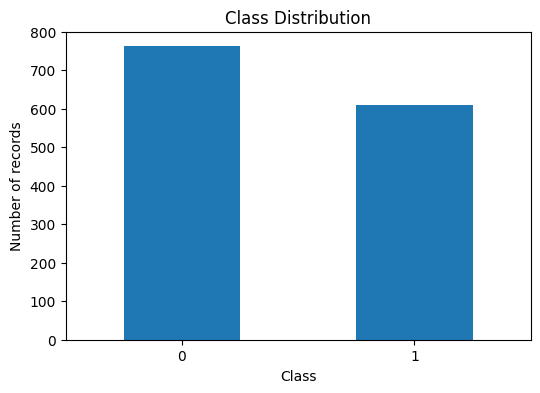

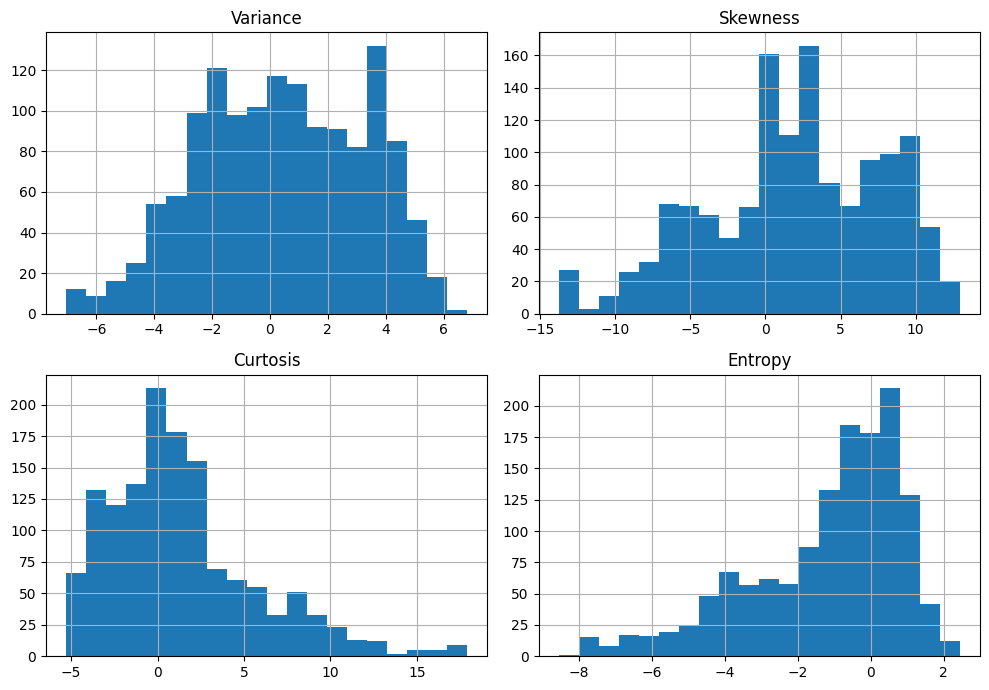

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
df["Class"].value_counts().sort_index().plot(kind="bar", ax=ax)
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()

df[["Variance", "Skewness", "Curtosis", "Entropy"]].hist(figsize=(10, 7), bins=20)
plt.tight_layout()
plt.show()

## Step 5 — Separate X and y

In [9]:
X = df[["Variance", "Skewness", "Curtosis", "Entropy"]]
y = df["Class"]
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (1372, 4)
Target shape: (1372,)


## Step 6 — Train-test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1097
Testing records: 275


## Step 7 — Train Logistic Regression

In [11]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## Step 8 — Predict class labels

In [12]:
y_pred = model.predict(X_test)
results = pd.DataFrame({"Actual Class": y_test.values, "Predicted Class": y_pred})
display(results.head(15))
print("Correct predictions:", (results["Actual Class"] == results["Predicted Class"]).sum())
print("Incorrect predictions:", (results["Actual Class"] != results["Predicted Class"]).sum())

,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,1
6,0,0
7,0,0
8,0,0
9,1,1


Correct predictions: 267
Incorrect predictions: 8


## Step 9 — Predict probabilities

In [13]:
y_probability = model.predict_proba(X_test)
probability_results = pd.DataFrame(y_probability, columns=["Probability of Class 0", "Probability of Class 1"])
display(probability_results.head())

,Probability of Class 0,Probability of Class 1
0,0.999576,0.000424
1,0.033572,0.966428
2,0.755631,0.244369
3,0.035568,0.964432
4,0.006959,0.993041


## Step 10 — Evaluation

In [14]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.9709090909090909
Precision: 0.9384615384615385
Recall   : 1.0
F1-score : 0.9682539682539683

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



## Step 11 — Confusion matrix

Confusion Matrix:
 [[145   8]
 [  0 122]]


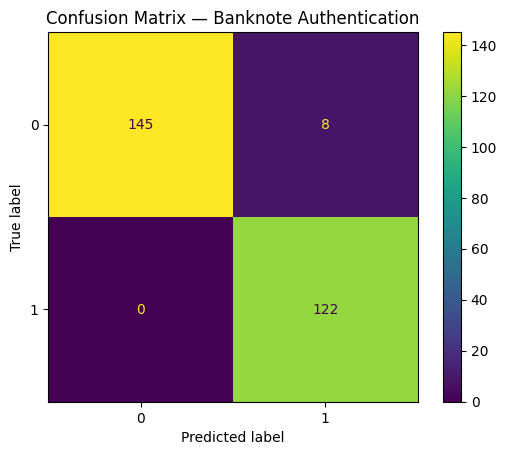

In [15]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion Matrix:\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1]).plot()
plt.title("Confusion Matrix — Banknote Authentication")
plt.show()

## Step 12 — Threshold comparison

In [16]:
class_1_probability = model.predict_proba(X_test)[:, 1]
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    threshold_pred = (class_1_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, threshold_pred),
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1-score": f1_score(y_test, threshold_pred, zero_division=0)
    })
display(pd.DataFrame(threshold_rows))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.970909,0.938462,1.0,0.968254
1,0.5,0.970909,0.938462,1.0,0.968254
2,0.7,0.996364,0.991870,1.0,0.995918


## Extension — 5-fold StratifiedKFold

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [0.98181818 0.97818182 0.97810219 0.97445255 0.99270073]
Mean accuracy: 0.9810510948905108
Standard deviation: 0.006273307597626086


## Extension — Compare Decision Tree

In [18]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, tree_pred)],
    "Precision": [precision_score(y_test, y_pred, zero_division=0), precision_score(y_test, tree_pred, zero_division=0)],
    "Recall": [recall_score(y_test, y_pred, zero_division=0), recall_score(y_test, tree_pred, zero_division=0)],
    "F1-score": [f1_score(y_test, y_pred, zero_division=0), f1_score(y_test, tree_pred, zero_division=0)]
})
display(comparison)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.970909,0.938462,1.0,0.968254
1,Decision Tree,0.992727,0.983871,1.0,0.991870


## Extension — Effect of C

In [19]:
c_rows = []
for c in [0.01, 0.1, 1, 10, 100]:
    candidate = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=1000))
    candidate.fit(X_train, y_train)
    pred = candidate.predict(X_test)
    c_rows.append({
        "C": c,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })
display(pd.DataFrame(c_rows))

,C,Accuracy,Precision,Recall,F1-score
0,0.01,0.938182,0.941176,0.918033,0.929461
1,0.10,0.970909,0.938462,1.000000,0.968254
2,1.00,0.970909,0.938462,1.000000,0.968254
3,10.00,0.985455,0.968254,1.000000,0.983871
4,100.00,0.985455,0.968254,1.000000,0.983871


## Extension — Prediction function

In [20]:
def predict_banknote(variance, skewness, curtosis, entropy):
    sample = pd.DataFrame([{"Variance": variance, "Skewness": skewness, "Curtosis": curtosis, "Entropy": entropy}])
    pred = int(model.predict(sample)[0])
    probs = model.predict_proba(sample)[0]
    return {
        "predicted_class": pred,
        "probability_class_0": float(probs[0]),
        "probability_class_1": float(probs[1])
    }

# Example execution:
# print(predict_banknote(3.6, 8.6, -2.8, -0.4))

## Extension — Evaluate on Selected Predictions File
Let's load the newly provided dataset at `/content/Banknote_Predictions.csv` and inspect its shape and columns.

In [21]:
predictions_df = pd.read_csv('/content/Banknote_Predictions.csv')
print("Shape of Banknote_Predictions.csv:", predictions_df.shape)
display(predictions_df.head())
predictions_df.info()

Shape of Banknote_Predictions.csv: (275, 2)


,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Actual Class     275 non-null    int64
 1   Predicted Class  275 non-null    int64
dtypes: int64(2)
memory usage: 4.4 KB


## Extension — Performance Metrics of the Predictions File
We will now calculate standard metrics like Accuracy, Precision, Recall, and F1-score for the prediction set inside `Banknote_Predictions.csv`.

Accuracy : 0.9709090909090909
Precision: 0.9384615384615385
Recall   : 1.0
F1-score : 0.9682539682539683

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275

Confusion Matrix:
 [[145   8]
 [  0 122]]


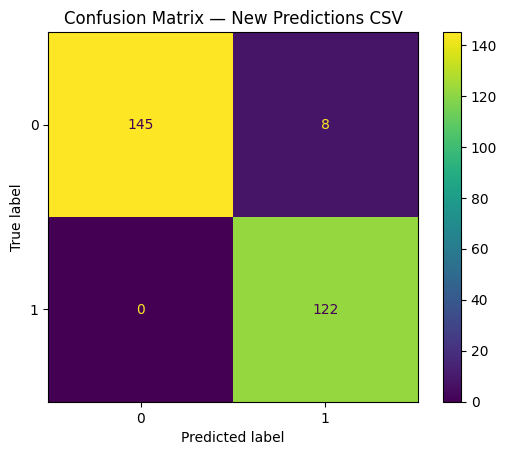

In [22]:
y_true_new = predictions_df['Actual Class']
y_pred_new = predictions_df['Predicted Class']

print("Accuracy :", accuracy_score(y_true_new, y_pred_new))
print("Precision:", precision_score(y_true_new, y_pred_new, zero_division=0))
print("Recall   :", recall_score(y_true_new, y_pred_new, zero_division=0))
print("F1-score :", f1_score(y_true_new, y_pred_new, zero_division=0))
print("\nClassification Report:\n", classification_report(y_true_new, y_pred_new, zero_division=0))

# Display Confusion Matrix
cm_new = confusion_matrix(y_true_new, y_pred_new, labels=[0, 1])
print("Confusion Matrix:\n", cm_new)
ConfusionMatrixDisplay(confusion_matrix=cm_new, display_labels=[0, 1]).plot()
plt.title("Confusion Matrix — New Predictions CSV")
plt.show()